In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path

sys.path.append(str(Path("..").resolve()))

In [3]:
#%pip install pandas
from scripts_.load_csv_data import parse_keyence_csv_file, parse_created_csv_file
from scripts_.load_vk_data import parse_vk4_file, parse_vk6_file, parse_vk4_file_stitched_tile
from scripts_.plot_csv_data import plot_keyence_csv_height, plot_csv_height
from scripts_.plot_vk_data import plot_vk4_height
from scripts_.stitching_csv_data import plot_stitched_height_image_from_csv
from scripts_.stitching_vk_data import plot_stitched_height_image_from_vk
from scripts_.tilt_correction import baseplane_filter
from scripts_.vk_height_to_csv import vk_height_to_csv, convert_vk_folder_to_csv

**Loading single vk4 Files** 

In [4]:
file_name_1 = Path("../raw_data_vk/Salt sample sanded 50x/20260507154445_Y1_X1.vk4")

with open(file_name_1, 'rb') as f:
    data_1_vk4 = parse_vk4_file(f)

**Loading single vk6 Files**

Vk6 files contain some additional meta data and a vk4 file.\
If the image was taken with 'Laser confocal', the individual tiles of stitched images are stored as vk4 files. If the image was taken with 'Focus variation', the individual tiles are stored as vk6 files.\
Vk4 files of stitched image tiles that were saved as vk6 need to be parsed with 'parse_vk4_file_stitched_tile' because they are missing the light data.\
The reason for this is unknown so far, but as only the height data is of interest, it does not affect the analysis.\
Additionally, as 'Laser confocal' is the prefered imaging mode, the 'parse_vk4_file_stitched_tile' function will likely not be relevant for the analysis.

In [5]:
file_name_2 = Path("../raw_data_vk/Paper with marker points 10x/20260513140757_Y1_X1.vk6")

data_2_vk6 = parse_vk6_file(file_name_2)   # extracts meta data and the vk4 file
data_2_vk4 = parse_vk4_file_stitched_tile(data_2_vk6['Vk4File'])  # use parse_vk4_file for individually taken images

**Loading single csv Files**

Csv Files created by the Keyence software:

In [6]:
#file_name_3 = Path("../keyence_csv/20260513140757_Y1_X1_Height.csv")
file_name_3 = Path("../keyence_csv/Paper with marker points 10x/20260513140757_Y1_X1_Height.csv")

data_3_csv, calibration = parse_keyence_csv_file(file_name_3)

Csv Files created by the 'vk_height_to_csv' function:

In [7]:
file_name_4 = Path("../processed_data_csv/Salt sample sanded 50x/20260507154445_Y1_X1_csv.csv")

data_4_csv, calibration = parse_created_csv_file(file_name_4)

**Plotting Height Data from single vk4/vk6 Files**

Either an image that was taken individually or a tile from a stitched image

Vk4:

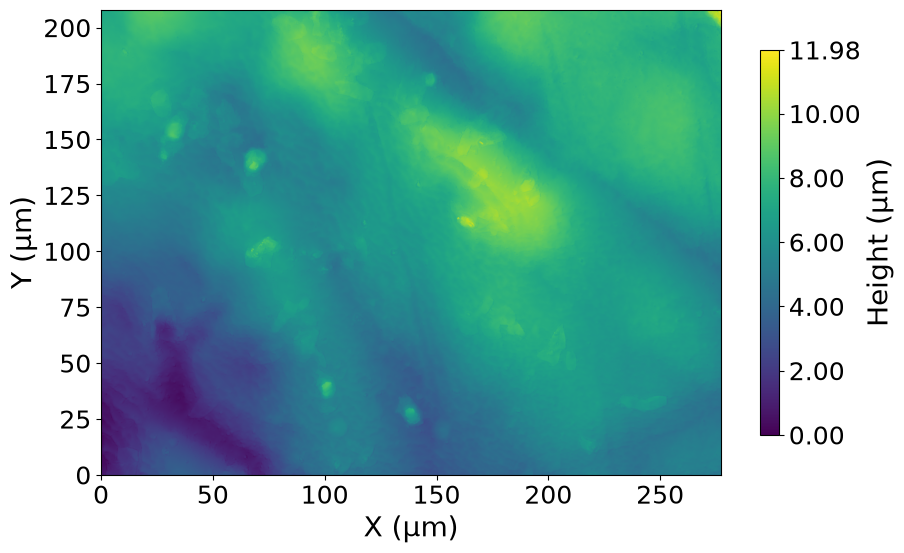

In [8]:
# orginal
ax11 = plot_vk4_height(data_1_vk4)

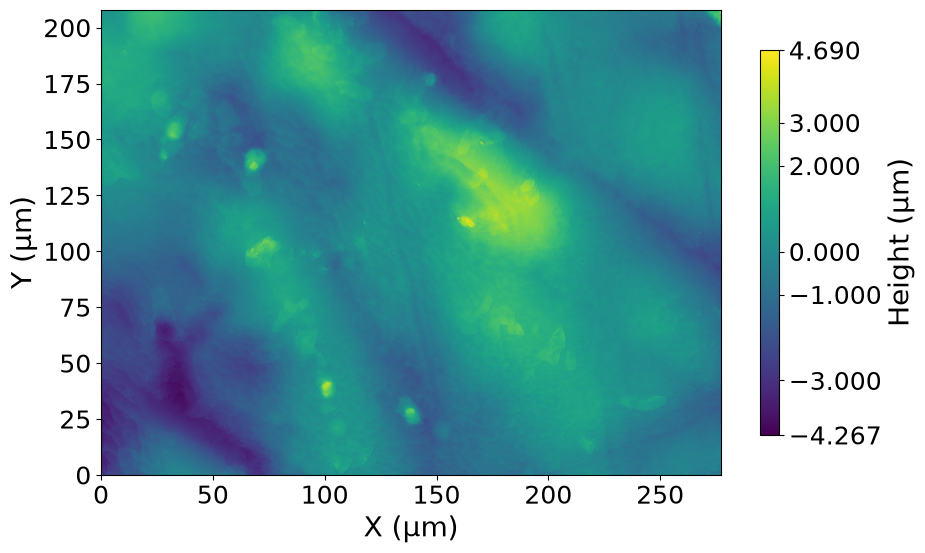

In [9]:
# tilt corrected
data_1_vk4_tiltcorr = baseplane_filter(data_1_vk4, 10)
ax12 = plot_vk4_height(data_1_vk4_tiltcorr, data_type='baseplane_subtracted')

Vk6:

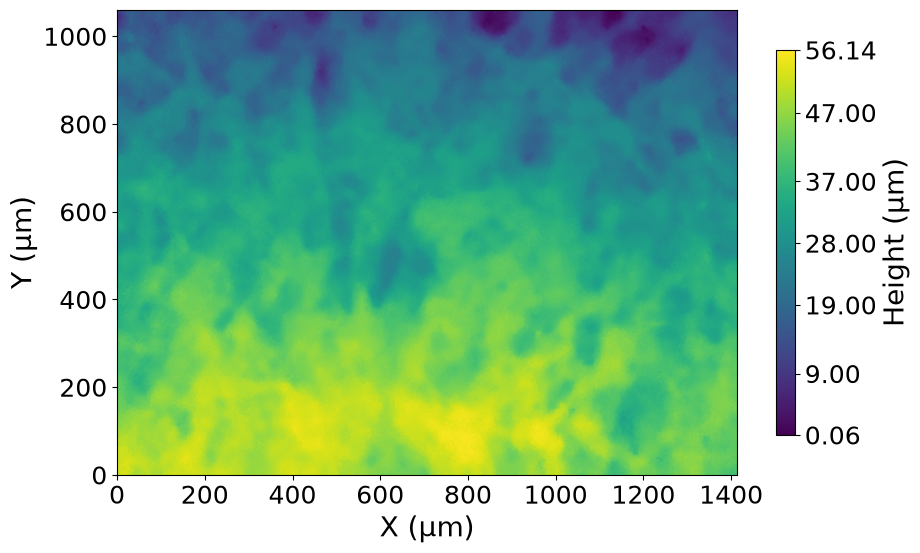

In [10]:
# orginal
ax21 = plot_vk4_height(data_2_vk4)

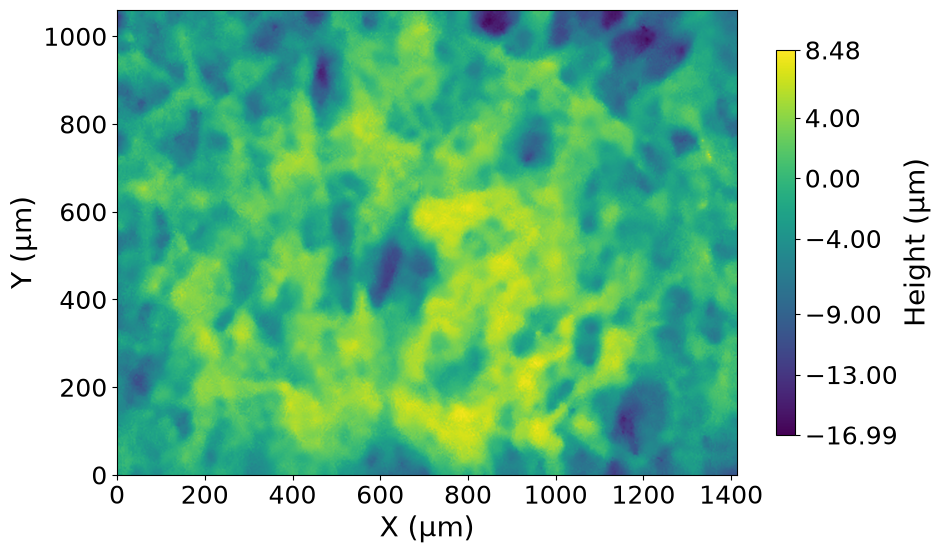

In [11]:
# tilt corrected
data_2_vk4_tiltcorr = baseplane_filter(data_2_vk4, 10)
ax22 = plot_vk4_height(data_2_vk4_tiltcorr, data_type='baseplane_subtracted')

**Plotting Height Data from single csv Files**

Csv files created by the Keyence software:

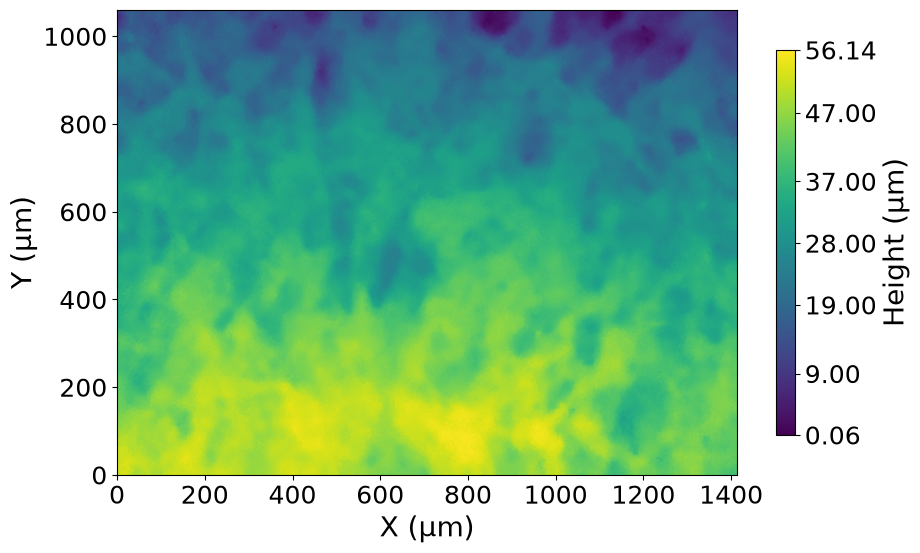

In [12]:
# original
ax3 = plot_keyence_csv_height(file_name_3)

Csv Files created by the 'vk_height_to_csv' function:

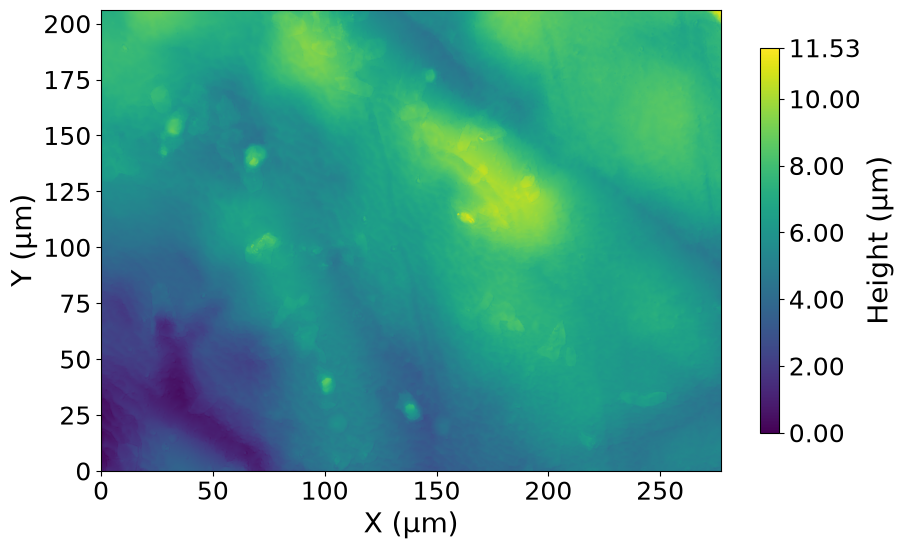

In [13]:
# original
ax4 = plot_csv_height(file_name_4)

**Creating csv Files from Height Data in vk4/vk6 Files**

In [14]:
# either convert a whole folder

#convert_vk_folder_to_csv(Path("../raw_data_vk/Salt sample sanded 50x"), output_folder=None)
# None creates a subfolder 'csv_output' inside folder 

convert_vk_folder_to_csv(
    Path("../raw_data_vk/Salt sample sanded 50x"),
    output_folder=None,
    data_type="original"
)

Saved: ..\processed_data_csv\Salt sample sanded 50x\20260507154445_Y1_X1_csv.csv
Saved: ..\processed_data_csv\Salt sample sanded 50x\20260507154445_Y1_X2_csv.csv
Saved: ..\processed_data_csv\Salt sample sanded 50x\20260507154445_Y2_X1_csv.csv
Saved: ..\processed_data_csv\Salt sample sanded 50x\20260507154445_Y2_X2_csv.csv


In [15]:
# or single files

vk_height_to_csv(Path("../raw_data_vk/Paper with marker points 10x/20260513140757_Y1_X1.vk6"), output_dir=None)
# None puts created csv file in same folder

WindowsPath('../processed_data_csv/Paper with marker points 10x/20260513140757_Y1_X1_csv.csv')

**Stitching vk4/vk6 Files**

If mode is set to 'tilt_corr', tiles are tilt corrected individually before stitching.

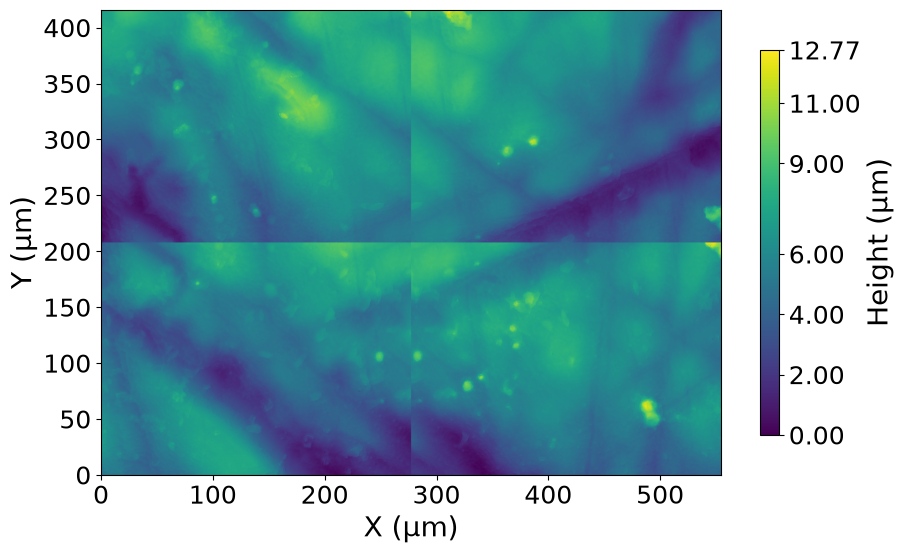

In [16]:
# original
ax5 = plot_stitched_height_image_from_vk(Path("../raw_data_vk/Salt sample sanded 50x/20260507154445_Y*_X*.vk4"), 'orig', overlap_x_um=0, overlap_y_um=0)
# also works for vk6 files

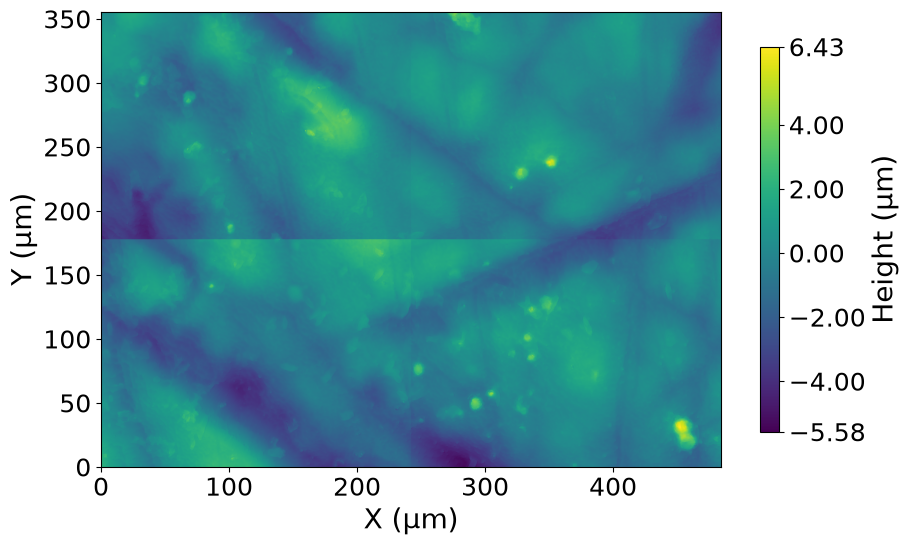

In [17]:
# tilt corrected and overlap cut off
ax6 = plot_stitched_height_image_from_vk(Path("../raw_data_vk/Salt sample sanded 50x/20260507154445_Y*_X*.vk4"), 'tilt_corr', overlap_x_um=35, overlap_y_um=30)
# also works for vk6 files

**Stitching csv Files**

Tilt correction still needs to be added inside 'plot_stitched_height_image_from_csv' function.

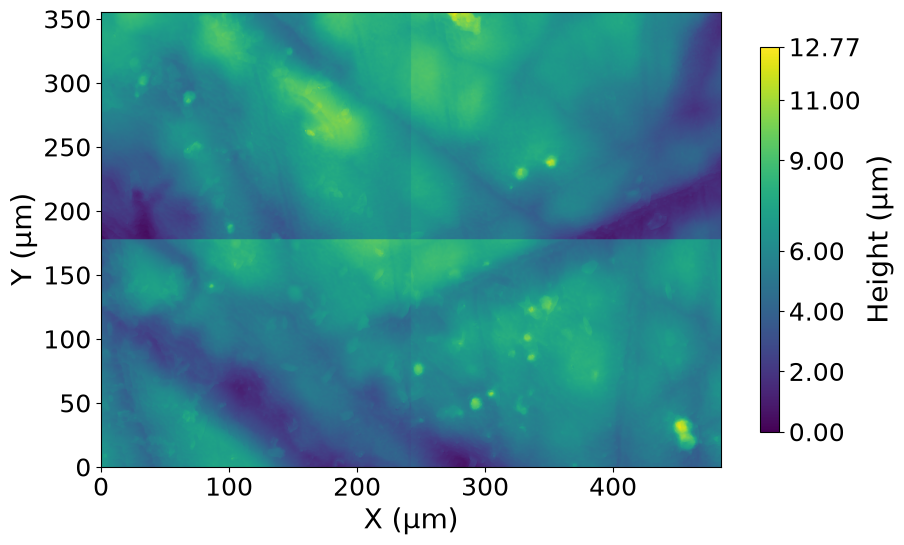

In [18]:
# tilt corrected and overlap cut off
ax8 = plot_stitched_height_image_from_csv(Path("../processed_data_csv/Salt sample sanded 50x/20260507154445_Y*_X*_csv.csv"), 'tilt_corr', overlap_x_um=35, overlap_y_um=30)